# Seminar 9 · Stable Diffusion
**Deep Generative Models · MIPT / YSDA (ШАД) · 19 November 2026**

In Imagen, the reverse process produced an image at each resolution. What if we asked a diffusion model to generate the input of an image decoder instead? Follow a photograph of a teapot through training, then generate one from a caption.

[Sampling lab](seminar9_SD.ipynb) · [Course repository](https://github.com/r-isachenko/2026-DGM-MIPT-YSDA-course)

## 1. Where should diffusion run?
For a $512 \times 512$ RGB photograph, pixel diffusion tracks $3 \times 512 \times 512$ numbers. The SD 1.5 autoencoder maps it to a grid of $4 \times 64 \times 64$ numbers. This gives 64 times fewer spatial positions and 48 times fewer scalar coordinates. The U-Net revisits this smaller grid at every step. The actual speedup depends on the network and hardware.

**Question.** If the encoder discards a tiny inscription on the teapot, how could we discover that before running diffusion? Encode and decode the reference photo, then inspect the inscription. A generator can invent plausible lettering even when the original letters are lost.

[SD 1.5 model card](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5)

## 2. Read the latent diffusion diagram

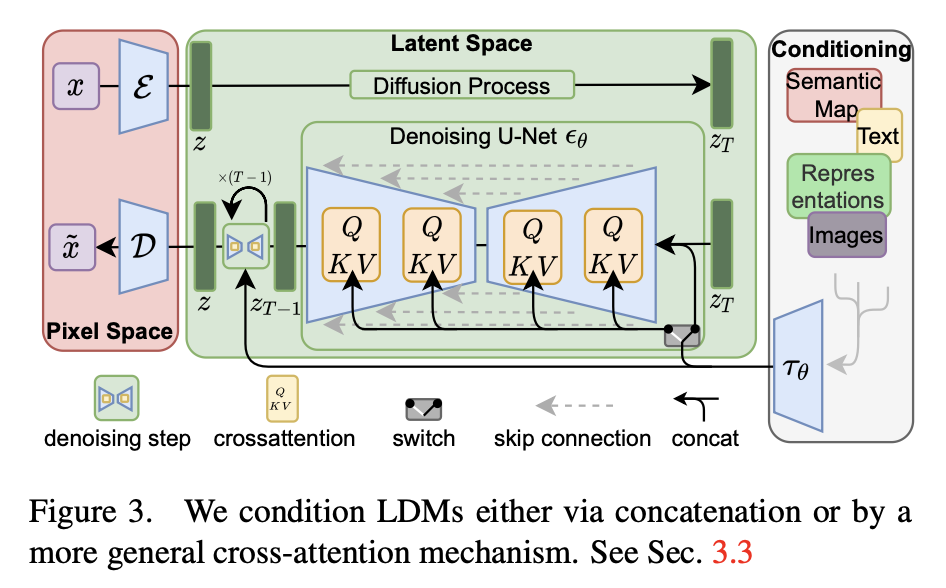

Follow the arrows in three passes. **Left:** the encoder $E$ takes the training image into a spatial latent. **Right:** a condition encoder turns a caption into a sequence of features. **Center:** the denoiser reads the noisy latent, time and condition. During text-to-image sampling, initialize this grid with Gaussian noise and decode the final grid with $D$.

The paper studies several kinds of conditioning. Today we follow the text branch in SD 1.5. Its first stage uses continuous KL-regularized latents.

[Rombach et al., Fig. 3](https://arxiv.org/abs/2112.10752)

## 3. What gets trained?
| Stage | Inputs | Prediction or reconstruction | Learning signal |
|---|---|---|---|
| Autoencoder | Real image $x$ | $D(u)$, where $u$ is sampled from the encoder posterior | Pixel/perceptual reconstruction and a patch discriminator encourage fidelity. KL regularizes the posterior. |
| Latent diffusion | Noisy latent $z_t$, time $t$, caption features $h$ | U-Net output with the shape of $z_t$ | Squared error against the noise used to build $z_t$. The pretrained VAE and CLIP text encoder are frozen. |

For SD 1.5, write $z_0=k u$ with $k$ the checkpoint's VAE scaling factor. For each image-caption pair, sample $t$ and $\epsilon\sim\mathcal N(0,I)$ and form

$$z_t=\sqrt{\bar\alpha_t}\,z_0+\sqrt{1-\bar\alpha_t}\,\epsilon,\qquad
\mathcal L=\mathbb E\big[\|\epsilon-\epsilon_\theta(z_t,t,h)\|_2^2\big].$$

The sampled noise supplies the target. At generation time the trained network estimates it from the current latent. SD 1.5 dropped text conditioning on 10% of examples during its final training stage, enabling both CFG predictions from one model.

[Rombach et al., §3](https://arxiv.org/abs/2112.10752) · [SD 1.5 training details](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5)

## 4. How does the U-Net keep the handle in place?

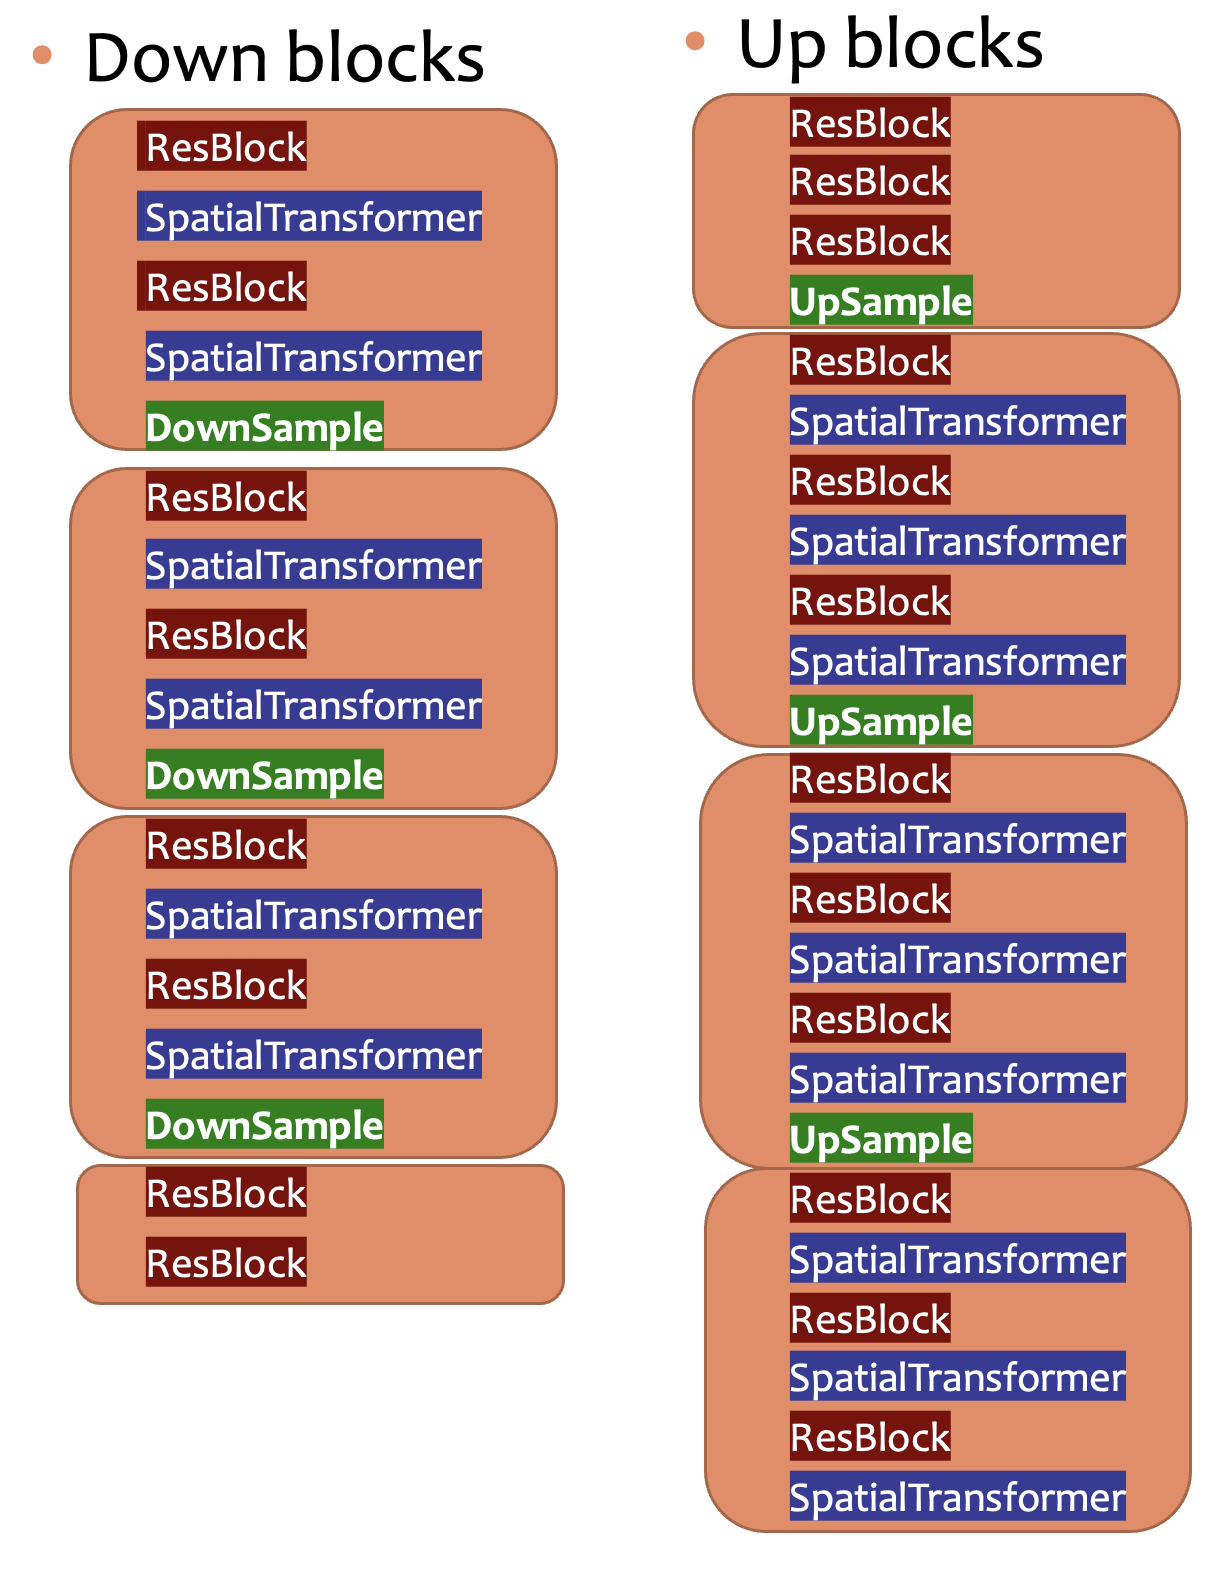

Trace a feature from the upper left down to the bottleneck. Coarser resolutions combine information across distant locations, such as the handle and the spout. Trace the skip connection across the U: the up block receives spatially aligned features from the down path. This helps it recover local detail. A time embedding tells residual blocks how noisy the input is.

The down/up paths run **inside one denoising evaluation**. The next sampler step calls the same U-Net again at a different time.

[Binxu Wang, Understanding Stable Diffusion from Scratch](https://scholar.harvard.edu/binxuw/classes/machine-learning-scratch/materials/stable-diffusion-scratch)

## 5. How does “red ceramic” reach a position?

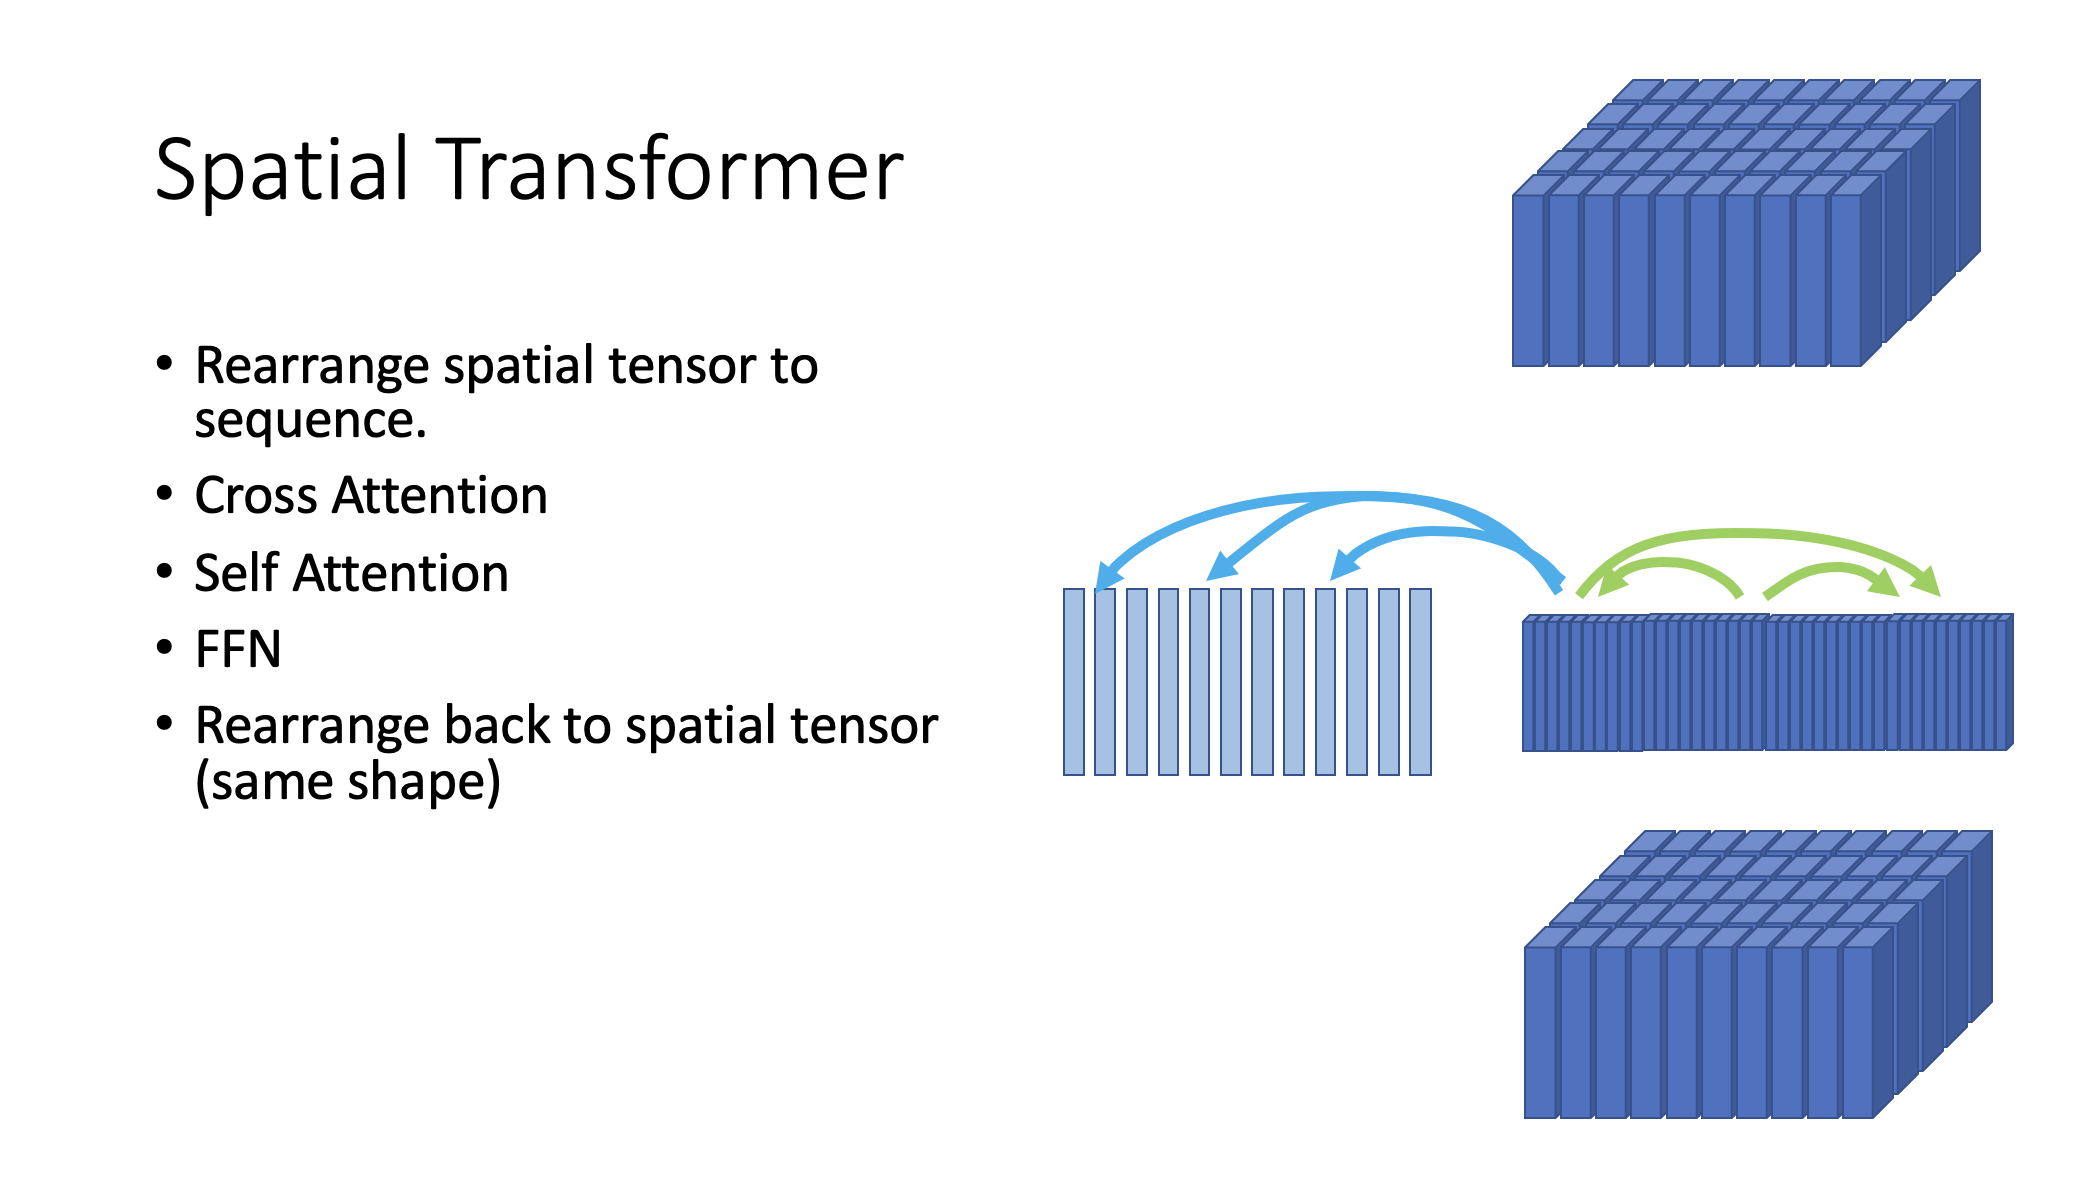

Flatten an intermediate feature map into $N=H W$ spatial vectors $F$. Encode the caption into $L=77$ token positions (including padding), with 768 features per position for SD 1.5. For one attention head,

$$Q=F W_Q,quad K=h W_K,quad V=h W_V,qquad
A=\operatorname{softmax}_{\rm tokens}\!\left(\frac{QK^\top}{\sqrt d}\right),\qquad O=A V.$$

Read one row of $A\in\mathbb R^{N\times L}$: for one spatial position, its weights across text tokens sum to one. A position on the teapot can use color and material cues from multiple tokens. In self-attention the keys and values also come from spatial features. In cross-attention they come from the text sequence. CLIP's image encoder is unnecessary in this sampling path.

[Binxu Wang, spatial transformer](https://scholar.harvard.edu/binxuw/classes/machine-learning-scratch/materials/stable-diffusion-scratch) · [LDM, §3.3](https://arxiv.org/abs/2112.10752)

## 6. One reverse step, then one decode
1. Encode the empty caption and the requested caption once. Draw $z_T\sim\mathcal N(0,I)$.
2. At time $t$, pass the same $z_t$ to both branches of the U-Net. Combine their predictions with $\hat\epsilon_s=\epsilon_\varnothing+s(\epsilon_c-\epsilon_\varnothing)$.
3. Pass $z_t$, $t$ and $\hat\epsilon_s$ to the scheduler. Its update gives the next latent on the chosen time grid. Repeat until the end.
4. Undo the scale and decode $D(z_0/k)$ to RGB.

**Connection to Imagen.** Pixel values have a display range. SD's four latent channels are learned coordinates with their own scale. Applying Imagen's pixel threshold directly to this grid would alter the denoiser's state. In the lab the DDIM scheduler uses the checkpoint configuration with latent clipping disabled.

[Diffusers pipeline walkthrough](https://huggingface.co/docs/diffusers/using-diffusers/write_own_pipeline)

## 7. From text-to-image to img2img
Start with a photograph we want to edit. Encode it to $z_{
m src}$ and pick a time on the DDIM grid. Form $z_t=\sqrt{\bar\alpha_t}\,z_{\rm src}+\sqrt{1-\bar\alpha_t}\,\epsilon$. Run the remaining reverse steps with a new caption, then decode.

| Control | Where it acts | What to inspect in the lab |
|---|---|---|
| Guidance scale $s$ | Relative contribution of the caption at each denoising step | Is the teapot red? Are its texture and shadow still plausible? |
| Number of steps | Discretization of the reverse path | Does the handle meet the body? Is the spout coherent? |
| Img2img strength | Starting noise level and remaining length of the reverse path | Is the silhouette preserved when changing a photo into a watercolor? |

**Before opening the lab:** Which comparison needs identical initial noise? Which also needs identical source-image encoding and corruption noise? Choose one visible feature to track in each row. [Open the sampling lab](seminar9_SD.ipynb)